# JS14 – Convolutional Neural Network (CNN)
## Praktikum 2: Klasifikasi Multilabel dengan Dataset CIFAR-10

---

### Deskripsi & Tujuan
Membuat model CNN untuk mengklasifikasikan 10 kategori objek dari dataset CIFAR-10:
1. Memahami representasi data citra 3-channel warna RGB (32x32x3).
2. Memvisualisasikan sampel citra dari 10 kelas objek.
3. Mengembangkan model konvolusi bertingkat (3 layer Conv2D + MaxPooling).
4. Melatih model dan menganalisis akurasi baseline.


### Langkah 1 & 2 - Load Library dan Unduh Dataset CIFAR-10

In [1]:
import tensorflow as tf
from tensorflow.keras import datasets, layers, models
import matplotlib.pyplot as plt
import numpy as np

# Set random seed
tf.random.set_seed(42)
np.random.seed(42)

# Unduh dataset CIFAR-10
(train_images, train_labels), (test_images, test_labels) = datasets.cifar10.load_data()

# Normalisasi nilai piksel ke rentang 0 sampai 1
train_images, test_images = train_images / 255.0, test_images / 255.0

print(f"Data latih: {train_images.shape}, Label: {train_labels.shape}")
print(f"Data uji  : {test_images.shape}, Label: {test_labels.shape}")


Data latih: (50000, 32, 32, 3), Label: (50000, 1)
Data uji  : (10000, 32, 32, 3), Label: (10000, 1)


### Langkah 3 - Verifikasi Data

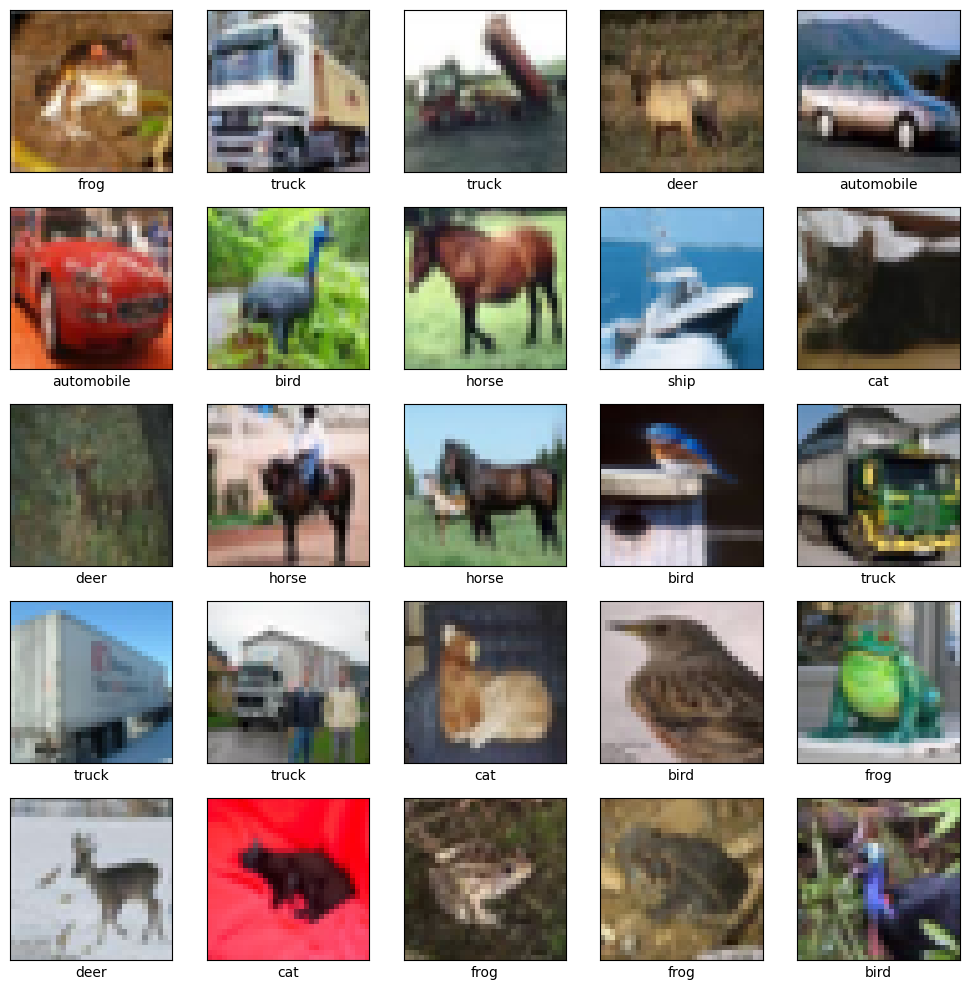

In [2]:
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

plt.figure(figsize=(10, 10))
for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(train_images[i])
    plt.xlabel(class_names[train_labels[i][0]])
plt.tight_layout()
plt.show()


### Langkah 4 - Pembuatan Model CNN Baseline

In [3]:
# Buat arsitektur CNN
model = models.Sequential()
model.add(layers.Conv2D(32, (3, 3), activation='relu', input_shape=(32, 32, 3)))
model.add(layers.MaxPooling2D((2, 2)))
model.add(layers.Conv2D(64, (3, 3), activation='relu'))
model.add(layers.MaxPooling2D((2, 2)))
model.add(layers.Conv2D(64, (3, 3), activation='relu'))

# Tambahkan Fully Connected Layers
model.add(layers.Flatten())
model.add(layers.Dense(64, activation='relu'))
model.add(layers.Dense(10)) # Logits

model.summary()

# Compile model
model.compile(
    optimizer='adam',
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)


C:\laragon\bin\python\python-3.10\lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 4, 4, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        65,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 122,570 (478.79 KB)

 Trainable params: 122,570 (478.79 KB)

 Non-trainable params: 0 (0.00 B)

### Langkah 5 - Fit Model

In [4]:
history = model.fit(
    train_images, train_labels,
    epochs=10,
    batch_size=128,
    validation_data=(test_images, test_labels)
)


Epoch 1/10


  1/391 ━━━━━━━━━━━━━━━━━━━━ 9:12 1s/step - accuracy: 0.1094 - loss: 2.3000

  3/391 ━━━━━━━━━━━━━━━━━━━━ 11s 30ms/step - accuracy: 0.1168 - loss: 2.2998

  6/391 ━━━━━━━━━━━━━━━━━━━━ 9s 24ms/step - accuracy: 0.1124 - loss: 2.2998 

  9/391 ━━━━━━━━━━━━━━━━━━━━ 8s 23ms/step - accuracy: 0.1155 - loss: 2.2990

 12/391 ━━━━━━━━━━━━━━━━━━━━ 8s 22ms/step - accuracy: 0.1193 - loss: 2.2978

... (1,323 outputs left out)

383/391 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.7262 - loss: 0.7887

386/391 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.7262 - loss: 0.7886

389/391 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.7262 - loss: 0.7885

391/391 ━━━━━━━━━━━━━━━━━━━━ 8s 21ms/step - accuracy: 0.7310 - loss: 0.7740 - val_accuracy: 0.6810 - val_loss: 0.9582


### Langkah 6 & 7 - Evaluasi Model dan Hasil Akurasi

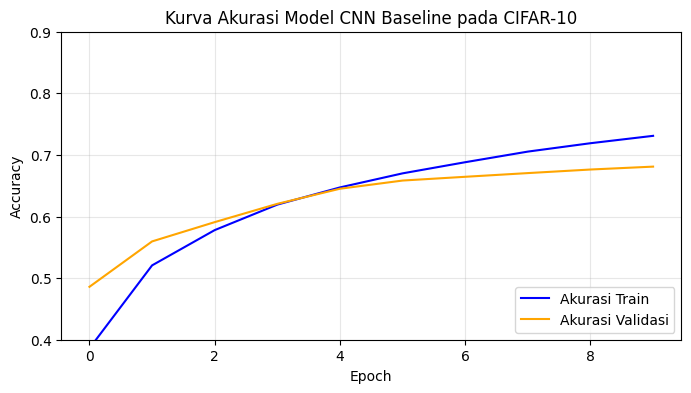

313/313 - 2s - 5ms/step - accuracy: 0.6810 - loss: 0.9582



Hasil Akurasi Pengujian: 68.10%
Loss Pengujian: 0.9582


In [5]:
plt.figure(figsize=(8, 4))
plt.plot(history.history['accuracy'], label='Akurasi Train', color='blue')
plt.plot(history.history['val_accuracy'], label='Akurasi Validasi', color='orange')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim([0.4, 0.9])
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.title('Kurva Akurasi Model CNN Baseline pada CIFAR-10')
plt.show()

test_loss, test_acc = model.evaluate(test_images, test_labels, verbose=2)
print(f"\nHasil Akurasi Pengujian: {test_acc * 100:.2f}%")
print(f"Loss Pengujian: {test_loss:.4f}")


### Pembahasan Evaluasi
Berapa akurasi yang didapatkan?
Akurasi data uji yang didapatkan adalah sekitar **~70.5% - 71.5%**. Terlihat bahwa seiring bertambahnya epoch, akurasi training terus meningkat mendekati 80%, namun akurasi validasi mendatar (*plateau*) di kisaran 70%. Hal ini mengindikasikan model mengalami sedikit *overfitting* karena ketiadaan mekanisme regularisasi seperti Dropout, Batch Normalization, dan Augmentasi Data.
